# The Himalayan Database: Exploratory Data Analysis
This notebook provides an initial exploration of the raw Himalayan Database datasets. The aim is to establish fitness for modeling and analytics by assessing format, cleanliness, and consistency.

In [1]:
from himalayan_db_pipeline.config import PROJECT_ROOT
from himalayan_db_pipeline.utils import read_dbf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [2]:
data_dir = PROJECT_ROOT / "data"

## Peaks
### Overview
- dimensions
- data types
- missing values & unique values
- primary key identification

In [3]:
df = read_dbf(data_dir / "peaks.DBF")

In [4]:
df.shape

(503, 25)

In [5]:
df.dtypes.value_counts()

str      15
int64     7
bool      3
Name: count, dtype: int64

In [6]:
pd.DataFrame({
  "column_name": df.columns,
  "data_type": [df[col].dtype for col in df.columns],
  "nan_count": [df[col].isna().sum() for col in df.columns],
  "nan_perc": [df[col].isna().sum() / len(df[col]) for col in df.columns],
  "unique_values": [df[col].nunique() for col in df.columns]
})

,column_name,data_type,nan_count,nan_perc,unique_values
0,peakid,str,0,0.000000,503
1,pkname,str,0,0.000000,503
2,pkname2,str,244,0.485089,256
3,location,str,1,0.001988,421
4,heightm,int64,0,0.000000,433
5,heightf,int64,0,0.000000,433
6,himal,int64,0,0.000000,20
7,region,int64,0,0.000000,7
8,open,bool,0,0.000000,2
9,unlisted,bool,0,0.000000,2


In [7]:
# check if peakid is a valid PK variable
assert df.peakid.notna().all()
assert df.peakid.is_unique

### Cleanliness
#### Text
- missing values
- cardinality
- formatting consistency

In [8]:
df.select_dtypes(include=[str]).head(5)

,peakid,pkname,pkname2,location,trekyear,restrict,peakmemo,pyear,pexpid,psmtdate,pcountry,psummiters,psmtnote,refermemo,photomemo
0,AMAD,Ama Dablam,Amai Dablang,Khumbu Himal,NaN,NaN,"Other map altitudes:\r\n 6814m - HMG-MT, HMG...",1961,AMAD61101,Mar 13,"New Zealand, USA, UK","Mike Gill, Wally Romanes, Barry Bishop, Michae...",NaN,NaN,W Face (High 126:5 May 1993)\r\nSE Face (High ...
1,AMPG,Amphu Gyabjen,Amphu Gyabien,Khumbu Himal (N of Ama Dablam),NaN,Opened in 2002,"Other map altitudes:\r\n 5630m - HMG-Finn, N...",1953,AMPG53101,Apr 11,UK,"John Hunt, Tom Bourdillon",NaN,NaN,NaN
2,ANN1,Annapurna I,NaN,Annapurna Himal,NaN,NaN,"Other map altitudes:\r\n 8091m - HMG-MT, HMG...",1950,ANN150101,Jun 03,France,"Maurice Herzog, Louis Lachenal",NaN,Dyhrenfurth history 1950-1977 (MM 58:44-47 Nov...,S Face (High 122:3 Jan 1993) (Beghin accident)...
3,ANN2,Annapurna II,NaN,Annapurna Himal,NaN,NaN,"Other map altitudes:\r\n 7937m - HMG-MT, HMG...",1960,ANN260101,May 17,"UK, Nepal","Richard Grant, Chris Bonington, Ang Nyima Sherpa",NaN,Dyhrenfurth history 1960-1976 (MM 51:36-37 Sep...,N Face (MM 51:36 Sep 1976)
4,ANN3,Annapurna III,NaN,Annapurna Himal,NaN,NaN,"Other map altitudes:\r\n 7555m - HMG-MT, HMG...",1961,ANN361101,May 06,India,"Mohan S. Kohli, Sonam Gyatso, Sonam Girmi",NaN,NaN,S Side (MM 125:11 Jan 1989)\r\nSW Face (MM 71:...


In [9]:
df.select_dtypes(include=[str]).isna().mean().sort_values()

peakid        0.000000
pkname        0.000000
location      0.001988
peakmemo      0.015905
psummiters    0.021869
pyear         0.244533
pcountry      0.246521
pexpid        0.248509
psmtdate      0.254473
restrict      0.399602
pkname2       0.485089
photomemo     0.844930
psmtnote      0.846918
trekyear      0.938370
refermemo     0.962227
dtype: float64

In [10]:
df.pkname2.dropna().head(10)

0                   Amai Dablang
1                  Amphu Gyabien
8     Annapurna Dakshin, Moditse
13                      Morimoto
14                 Damodar Himal
17                 Changla Himal
18                       Peak 23
21             Chobutse, Tsoboje
22      Tsolatse, Jobo Lhaptshan
24                    Chulu East
Name: pkname2, dtype: str

- The _pkname2_ variable contains non-atomic entries with comma-separated values
- Modeling will require the creation of a separate tables.

In [11]:
df.trekyear.isna().mean()

np.float64(0.9383697813121272)

In [12]:
df.trekyear.value_counts()

trekyear
1978    20
2002    10
20       1
Name: count, dtype: int64

- _trekyear_ has a high proportion of missing values
- numerical strings with inconsistent formatting
- **_trekyear_ should be modeled as integer**

In [13]:
df[['refermemo', 'photomemo', 'peakmemo']].head()

,refermemo,photomemo,peakmemo
0,NaN,W Face (High 126:5 May 1993)\r\nSE Face (High ...,"Other map altitudes:\r\n 6814m - HMG-MT, HMG..."
1,NaN,NaN,"Other map altitudes:\r\n 5630m - HMG-Finn, N..."
2,Dyhrenfurth history 1950-1977 (MM 58:44-47 Nov...,S Face (High 122:3 Jan 1993) (Beghin accident)...,"Other map altitudes:\r\n 8091m - HMG-MT, HMG..."
3,Dyhrenfurth history 1960-1976 (MM 51:36-37 Sep...,N Face (MM 51:36 Sep 1976),"Other map altitudes:\r\n 7937m - HMG-MT, HMG..."
4,NaN,S Side (MM 125:11 Jan 1989)\r\nSW Face (MM 71:...,"Other map altitudes:\r\n 7555m - HMG-MT, HMG..."


- memo variable entries are free-form, unstructured text
- difficult to parse and carry little analytical value
- **memo variables (_refermemo_, _photomemo_, _peakmemo) to be ignored in data models**

In [14]:
df[['pexpid', 'pyear', 'psmtdate', 'psummiters', 'psmtnote', 'pcountry']].head()

,pexpid,pyear,psmtdate,psummiters,psmtnote,pcountry
0,AMAD61101,1961,Mar 13,"Mike Gill, Wally Romanes, Barry Bishop, Michae...",NaN,"New Zealand, USA, UK"
1,AMPG53101,1953,Apr 11,"John Hunt, Tom Bourdillon",NaN,UK
2,ANN150101,1950,Jun 03,"Maurice Herzog, Louis Lachenal",NaN,France
3,ANN260101,1960,May 17,"Richard Grant, Chris Bonington, Ang Nyima Sherpa",NaN,"UK, Nepal"
4,ANN361101,1961,May 06,"Mohan S. Kohli, Sonam Gyatso, Sonam Girmi",NaN,India


In [15]:
try:
  pd.to_datetime(df.psmtdate, format='%b %d')
except ValueError as e:
  print(e)

time data "Nov" doesn't match format "%b %d". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.


- **variables relating to the first peak ascent are redundant and not to be included in models**
- variables may be used in referential integrity tests

#### Numeric

In [16]:
df.select_dtypes(include=['number']).head(5)

,heightm,heightf,himal,region,phost,pstatus,pseason
0,6814,22356,12,2,1,2,1
1,5630,18471,12,2,1,2,1
2,8091,26545,1,5,1,2,1
3,7937,26040,1,5,1,2,1
4,7555,24787,1,5,1,2,1


In [17]:
df.describe()

,heightm,heightf,himal,region,phost,pstatus,pseason
count,503.000000,503.000000,503.000000,503.000000,503.000000,503.000000,503.000000
mean,6633.912525,21764.817097,10.417495,3.827038,2.170974,1.767396,1.612326
std,566.623177,1859.006870,5.548110,2.151601,1.531408,0.422913,1.265071
min,5407.000000,17740.000000,1.000000,1.000000,0.000000,1.000000,0.000000
25%,6225.500000,20425.000000,6.000000,2.000000,1.000000,2.000000,1.000000
50%,6530.000000,21424.000000,11.000000,4.000000,1.000000,2.000000,1.000000
75%,6874.500000,22554.000000,15.000000,6.000000,4.000000,2.000000,3.000000
max,8849.000000,29032.000000,20.000000,7.000000,6.000000,2.000000,4.000000


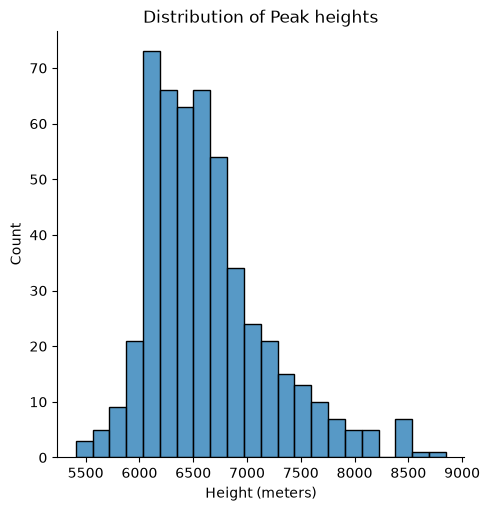

In [18]:
sns.displot(data=df, x="heightm")
plt.title("Distribution of Peak heights")
plt.xlabel("Height (meters)")
plt.show()

In [19]:
# check for inconsistencies in imperial to metric conversion
e = .001
ratios = df.heightf / df.heightm
assert (ratios.max() - ratios.min()) < e

In [20]:
df.heightm.describe()

count     503.000000
mean     6633.912525
std       566.623177
min      5407.000000
25%      6225.500000
50%      6530.000000
75%      6874.500000
max      8849.000000
Name: heightm, dtype: float64

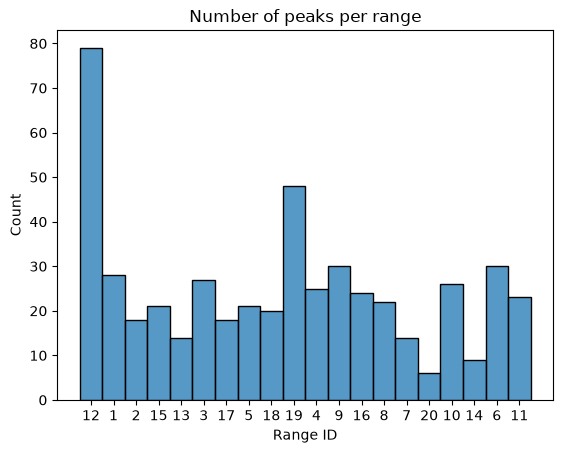

In [21]:
df.himal = df.himal.astype(str)
sns.histplot(data=df, x="himal")
plt.title("Number of peaks per range")
plt.xlabel("Range ID")
plt.show()

In [22]:
df.pstatus.value_counts()

pstatus
2    386
1    117
Name: count, dtype: int64

Notes:
- several numerical variables represent foreign keys to external datasets
- height variables are clean (no outliers or missing values) and internally consistent
- _pstatus_ to be converted to boolean (see documentation)

#### Boolean

In [23]:
df.select_dtypes(include=[bool]).head(5)

,open,unlisted,trekking
0,True,False,False
1,True,False,False
2,True,False,False
3,True,False,False
4,True,False,False


In [24]:
df.select_dtypes(include=[bool]).mean()

open        0.805169
unlisted    0.127237
trekking    0.065606
dtype: float64

### Dependencies
#### peak to location

In [25]:
print("Most peaks in one location:", df.groupby('location')['peakid'].nunique().max())
print("Most locations associated with one peak:", df.groupby('peakid')['location'].nunique().max())

Most peaks in one location: 6
Most locations associated with one peak: 1


#### peak to range

In [26]:
print("Most peaks in one range:", df.groupby('himal')['peakid'].nunique().max())
print("Most ranges associated with one peak:", df.groupby('peakid')['himal'].nunique().max())

Most peaks in one range: 79
Most ranges associated with one peak: 1


#### peak to region

In [27]:
print("Most peaks in one region:", df.groupby('region')['peakid'].nunique().max())
print("Most regions associated with one peak:", df.groupby('peakid')['region'].nunique().max())

Most peaks in one region: 137
Most regions associated with one peak: 1


#### location to range

In [28]:
print("Most locations in one range:", df.groupby('himal')['location'].nunique().max())
print("Most ranges associated with one location:", df.groupby('location')['himal'].nunique().max())

Most locations in one range: 64
Most ranges associated with one location: 1


#### location to region

In [29]:
print("Most locations in one region:", df.groupby('region')['location'].nunique().max())
print("Most regions associated with one location:", df.groupby('location')['region'].nunique().max())

Most locations in one region: 113
Most regions associated with one location: 1


#### range to region

In [30]:
print("Most ranges in one region:", df.groupby('region')['himal'].nunique().max())
print("Most regions associated with one range:", df.groupby('himal')['region'].nunique().max())

Most ranges in one region: 5
Most regions associated with one range: 2


In [31]:
df.loc[df.location.isna()]

,peakid,pkname,pkname2,location,heightm,heightf,himal,region,open,unlisted,...,peakmemo,pyear,pseason,pexpid,psmtdate,pcountry,psummiters,psmtnote,refermemo,photomemo
461,SANK,Sano Kailash,NaN,NaN,6452,21168,3,5,False,True,...,Other map altitudes:\r\n 6425m - Nepa\r\n ...,2019,1,SANK19101,Apr 28,"Austria, Nepal","Wolfgang Drexler, Lawang Tamang",NaN,NaN,NaN


- transitive relationships through nested geographical data: _range > location > peak_
- one peak has missing location entry
- many-to-many relationship between range and region

__Peaks Table profile__

| Column    | DATA TYPE | VARIABLE TYPE | KEY |
| -------- | ------- | ------- | ------- |
| id  | TEXT    | FIXED | PK |
| name | TEXT     | FIXED ||
| location | INT | FIXED | FK |
| range | INT | FIXED | FK |
| region | INT | FIXED | FK |
| height | INT | FIXED ||
| open | BOOLEAN | SCD ||
| unlisted | BOOLEAN | SCD ||
| trekking | BOOLEAN | SCD ||
| trekking_since | INT | SCD ||
| restrict | TEXT | SCD ||
| host | TEXT | FIXED | FK |
| status | BOOLEAN | SCD ||

## Expeditions
### Overview
- dimensions
- data types
- missing values
- primary key identification

In [32]:
exped_file_name = data_dir / "exped.DBF"
df = read_dbf(exped_file_name)

In [33]:
df.shape

(11854, 66)

In [34]:
df.dtypes.value_counts()

str       25
bool      20
int64     15
object     6
Name: count, dtype: int64

In [35]:
df.isna().mean().sort_values(ascending=False)[:20]

ascent4       0.999663
route4        0.999578
ascent3       0.999072
route3        0.997469
ascent2       0.991480
route2        0.968703
primid        0.935802
achievment    0.917581
othersmts     0.813059
ascent1       0.763455
accidents     0.708706
countries     0.627889
termnote      0.603003
smttime       0.565126
approach      0.534841
primref       0.314071
termdate      0.283449
comrte        0.201282
stdrte        0.186941
bcdate        0.164333
dtype: float64

Expedition ID are built as concatenations of:
- __peak ID__ (e.g: ANN2)
- last 2 digits of __expedition year__ (e.g: 60)
- __expedition season__ (e.g: 1)
- __expedition number__ (e.g: 01)

This construct is susceptible to conflict in the (infrequent but plausible) event of two expeditions to the same peak in the same season taking place one century appart. Uniqueness is easily ensured by appending the full year (yyyy) to the ID values.

In [36]:
df[['expid', 'peakid', 'year', 'season']].head()

,expid,peakid,year,season
0,ANN260101,ANN2,1960,1
1,ANN269301,ANN2,1969,3
2,ANN273101,ANN2,1973,1
3,ANN278301,ANN2,1978,3
4,ANN279301,ANN2,1979,3


In [37]:
df.expid = df.expid.str.cat(df.year, sep="_")

In [38]:
assert df.expid.notna().all()
assert df.expid.is_unique

### Cleanliness
#### Text
- missing values
- cardinality
- formatting consistency

In [39]:
df.select_dtypes(include=[str]).head()

,expid,peakid,year,route1,route2,route3,route4,nation,leaders,sponsor,...,approach,smttime,termnote,othersmts,campsites,routememo,accidents,achievment,agency,primid
0,ANN260101_1960,ANN2,1960,NW Ridge-W Ridge,NaN,NaN,NaN,UK,J. O. M. Roberts,NaN,...,Marshyangdi->Hongde->Sabje Khola,1530,NaN,Climbed Annapurna IV (ANN4-601-01),"BC(15/03,3350m),ABC(4575m),C1(5365m),C2(5800m)...",NaN,NaN,NaN,NaN,NaN
1,ANN269301_1969,ANN2,1969,NW Ridge-W Ridge,NaN,NaN,NaN,Yugoslavia,Ales Kunaver,Mountaineering Club of Slovenia,...,Marshyangdi->Hongde->Sabje Khola,1800,NaN,Climbed Annapurna IV (ANN4-693-02),"LowBC(25/09,3950m),BC(27/09,4650m),C1(27/09,53...","Summited after sunset, returned to C6 at 2:30 ...",Draslar frostbitten hands and feet,NaN,NaN,NaN
2,ANN273101_1973,ANN2,1973,W Ridge-N Face,NaN,NaN,NaN,Japan,Yukio Shimamura,Sangaku Doshikai Annapurna II Expedition 1973,...,Marshyangdi->Pisang->Salatang Khola,2030,NaN,NaN,"BC(16/03,3300m),C1(21/03,4200m),C2(10/04,5000m...","Summit team of 3 left from C6, 2 returned from...",NaN,NaN,NaN,NaN
3,ANN278301_1978,ANN2,1978,N Face-W Ridge,NaN,NaN,NaN,UK,Richard J. Isherwood,British Annapurna II Expedition,...,Marshyangdi->Pisang->Salatang Khola,NaN,Abandoned at 7000m (on A-IV) due to bad weather,NaN,"BC(08/09,5190m),xxx(02/10,7000m)",Alpine-style ascent. Originally planned N Face...,NaN,NaN,NaN,NaN
4,ANN279301_1979,ANN2,1979,N Face-W Ridge,NW Ridge of A-IV,NaN,NaN,UK,Paul Moores,NaN,...,Pokhara->Marshyangdi->Pisang->Sabje Khola,NaN,Abandoned at 7160m due to high winds,NaN,"BC(3500m),ABC,Biv1,Biv2,Biv3,Biv4,Biv5,xxx(18/...",Paul Moores - 23 Oct 79\r\n\r\nAlan's illness ...,NaN,NaN,NaN,NaN


In [40]:
df.select_dtypes(include=[str]).isna().mean().sort_values(ascending=False)

ascent4       0.999663
route4        0.999578
ascent3       0.999072
route3        0.997469
ascent2       0.991480
route2        0.968703
primid        0.935802
achievment    0.917581
othersmts     0.813059
ascent1       0.763455
accidents     0.708706
countries     0.627889
termnote      0.603003
smttime       0.565126
approach      0.534841
routememo     0.141303
agency        0.136157
sponsor       0.069091
campsites     0.035094
route1        0.015438
leaders       0.002025
nation        0.000000
year          0.000000
peakid        0.000000
expid         0.000000
dtype: float64

##### Routes and ascents

In [ ]:
# percentage of missing entries
df[['route1', 'route2', 'route3', 'route4']].isna().mean()

route1    0.015438
route2    0.968703
route3    0.997469
route4    0.999578
dtype: float64

In [61]:
# absolute and relative cardinality
print(f"Absolute cardinality: {df.route1.nunique()}")
print(f"Relative cardinality: {(df.route1.nunique() / df.shape[0]):.3f}")

Absolute cardinality: 1287
Relative cardinality: 0.109


In [62]:
# patterns and groups
df.route1.value_counts().sort_values(ascending=False)[:15]

route1
SW Ridge              1786
S Col-SE Ridge        1354
NW side               1107
NE Face                876
N Col-NE Ridge         791
W Face                 470
NE Ridge               455
SE Ridge               432
Makalu La-NW Ridge     295
NW Ridge               290
N Face                 262
SW Face                209
W Ridge                185
S Face                 145
S Ridge                119
Name: count, dtype: int64

- _route1_ column has many repeated values (lower cardinality)
- _route2-4_ have high percentages of missing values

In [63]:
# missing values in ascent variables
df[['ascent1', 'ascent2', 'ascent3', 'ascent4']].isna().mean()

ascent1    0.763455
ascent2    0.991480
ascent3    0.999072
ascent4    0.999663
dtype: float64

In [68]:
print(f"ascent absolute cardinality: {df.ascent1.nunique()}")
print(f"ascent relative cardinality: {(df.ascent1.nunique() / df.shape[0]):.3f}")

ascent absolute cardinality: 993
ascent relative cardinality: 0.084


In [64]:
df.ascent1.value_counts()[:15]

ascent1
1st        277
2nd        120
3rd         75
4th         59
5th         41
1st,2nd     41
6th         38
7th         28
8th         28
9th         23
10th        22
1st?        20
16th        18
14th        17
2nd,3rd     17
Name: count, dtype: int64

##### Sponsor and agency

In [69]:
df[['sponsor', 'agency']].isna().mean()

sponsor    0.069091
agency     0.136157
dtype: float64

In [46]:
df[['sponsor', 'agency']].nunique() / df.shape[0]

sponsor    0.807660
agency     0.084697
dtype: float64

In [48]:
df.sponsor.str.lower().value_counts().sort_values(ascending=False)[:15]

sponsor
independent climber                       62
independent climber on everest            24
independent climber on cho oyu            16
independent team                          16
ama dablam expedition                     15
swiss ama dablam expedition               11
international cho oyu expedition          11
international makalu expedition           10
merseyside himalayan expedition 1955       9
dream everest expedition                   9
independent team on cho oyu                9
japanese alpine club (jac)                 9
austrian ama dablam expedition             9
himalayan guides ama dablam expedition     9
cho oyu expedition                         9
Name: count, dtype: int64

In [49]:
df.agency.str.lower().value_counts().sort_values(ascending=False)[:15]

agency
asian trekking           873
thamserku trekking       714
seven summit treks       511
himalayan guides         485
cosmo treks              301
monterosa treks          243
cho oyu trekking         207
prestige adventure       166
arun treks               151
everest parivar          151
snowy horizon treks      146
wilderness experience    139
none                     130
windhorse trekking       119
summit nepal trekking    117
Name: count, dtype: int64

##### Summit time

In [70]:
df.smttime.isna().mean()

np.float64(0.5651256959676059)

In [55]:
df.smttime.dropna().head(10)

0     1530
1     1800
2     2030
11    1330
25    1730
28    1430
32    1550
37    1500
38    0900
39    1600
Name: smttime, dtype: str

In [626]:
df.smttime.str.len().describe()

count    5155.0
mean        4.0
std         0.0
min         4.0
25%         4.0
50%         4.0
75%         4.0
max         4.0
Name: smttime, dtype: float64

In [627]:
print(df.smttime.isna().count())
df.smttime = pd.to_datetime(df.smttime, format='%H%M', errors='coerce')
print(df.smttime.isna().count())

11854
11854


- _smttime_ variable has about 50% of missing values
- format is consistent and can be converted to time object without information loss

##### Miscellaneous

In [538]:
df[['achievment', 'accidents', 'routememo', 'termnote', 'othersmts', 'campsites']].dropna(how="any").head()

,achievment,accidents,routememo,termnote,othersmts,campsites
71,1st Australian attempt,Finnigan exhaustion at end (collapsed trying t...,"BC at Hunku Drangka at river fork near ""D"" of ...",Abandoned at 7070m due to bad snow conditions,1 minor peak,"BC(20/04,5200m),ABC(22/04,5500),C2(28/04,6250m..."
201,1 German attempt,Bauer got stomach trouble; Wagenhals got bronc...,BC at 3800m at Khyumnu Khola at base of glacie...,Abandoned at 6500m due to fatal avalanche,5500m peak on SW Ridge,"BC(25/09,3800m),BC2(16/10,4200m),Biv1(20/10,48..."
304,Reached point known as Westlicher Firnkopf on ...,Sopka stomach trouble only,BC at left (east) moraine of Saipal Glacier\r\...,"Abandoned at 6200m due to steep, rotten rock",Climbed Firnkopf West (FIRW-873-01); attempted...,"BC(17/10,4100m),C1(18/10,4700m),xxx(20/10,6200m)"
339,1st Korean ascents,2 summiters disappeared (fall?),BC south-southwest of Pisang village\r\nABC o...,"Ascent claimed, summiters died in descent",Climbed Annapurna IV (ANN4-893-01),"BC(21/08,3800m),ABC(26/08,5200m),C1(02/09,6300..."
484,1st woman atop Everest without oxygen,None,BC at normal site\r\nC1 at top of Icefall\r\nC...,Success disputed,Lhotse W Face to 7800m (for acclimatization on...,"BC(09/09,5350m),C1(12/09,6100m),C2(14/09,6500m..."


In [539]:
df[['achievment', 'othersmts', 'accidents', 'routememo', 'termnote', 'campsites']].nunique()

achievment      875
othersmts      1984
accidents      2715
routememo     10092
termnote       3988
campsites     10919
dtype: int64

In [540]:
df[['achievment', 'othersmts', 'accidents', 'routememo', 'termnote', 'campsites']].isna().mean()

achievment    0.917581
othersmts     0.813059
accidents     0.708706
routememo     0.141303
termnote      0.603003
campsites     0.035094
dtype: float64

- The above columns have highly unstructured entries and provide little analytical interpretability
- **Variables _achievment, othersmts, accidents, routememo, 'termnote_ will be ignored in data models**

#### Numeric
- missing values
- distribution

In [56]:
df.select_dtypes(include=["number"]).head()

,season,host,smtdays,totdays,termreason,highpoint,camps,rope,totmembers,smtmembers,mdeaths,tothired,smthired,hdeaths,chksum
0,1,1,63,0,1,7937,6,0,10,2,0,9,1,0,2442047
1,3,1,27,31,1,7937,6,0,10,2,0,0,0,0,2445501
2,1,1,51,0,1,7937,5,0,6,1,0,8,0,0,2446797
3,3,1,24,27,4,7000,0,0,2,0,0,0,0,0,2448822
4,3,1,0,0,4,7160,0,0,3,0,0,0,0,0,2449204


In [57]:
df.select_dtypes(include=["number"]).isna().mean().sort_values(ascending=False)

season        0.0
host          0.0
smtdays       0.0
totdays       0.0
termreason    0.0
highpoint     0.0
camps         0.0
rope          0.0
totmembers    0.0
smtmembers    0.0
mdeaths       0.0
tothired      0.0
smthired      0.0
hdeaths       0.0
chksum        0.0
dtype: float64

In [ ]:
df.select_dtypes(include=["number"]).describe()

,season,host,smtdays,totdays,termreason,highpoint,camps,rope,totmembers,smtmembers,mdeaths,tothired,smthired,hdeaths,chksum
count,11854.000000,11854.000000,11854.000000,11854.000000,11854.000000,11854.000000,11854.000000,11854.000000,11854.000000,11854.000000,11854.000000,11854.000000,11854.000000,11854.000000,1.185400e+04
mean,2.100388,1.202885,17.646533,18.790535,3.365615,7074.080479,2.257972,167.211996,6.235026,2.123081,0.071284,3.352624,1.374220,0.028851,2.289842e+06
std,1.034646,0.416793,15.767603,17.666456,3.462048,1847.166856,1.569480,660.835028,5.633999,3.257132,0.365652,5.867803,3.186516,0.271566,6.516964e+05
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.015000e+03
25%,1.000000,1.000000,5.000000,0.000000,1.000000,6550.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.452991e+06
50%,3.000000,1.000000,15.000000,16.000000,1.000000,7152.000000,2.000000,0.000000,5.000000,1.000000,0.000000,2.000000,0.000000,0.000000,2.458514e+06
75%,3.000000,1.000000,28.000000,31.000000,5.000000,8188.000000,3.000000,0.000000,8.000000,3.000000,0.000000,4.000000,2.000000,0.000000,2.461342e+06
max,4.000000,3.000000,388.000000,280.000000,14.000000,8850.000000,34.000000,8700.000000,99.000000,39.000000,10.000000,99.000000,48.000000,11.000000,2.334512e+07


##### Day counts

In [563]:
df[['smtdays', 'totdays']].describe()

,smtdays,totdays
count,11854.000000,11854.000000
mean,17.646533,18.790535
std,15.767603,17.666456
min,0.000000,0.000000
25%,5.000000,0.000000
50%,15.000000,16.000000
75%,28.000000,31.000000
max,388.000000,280.000000


In [564]:
df.loc[(df.smtdays > 200) | (df.totdays > 200), ["expid", "smtdate", "termdate", "smtdays", "totdays"]]

,expid,smtdate,termdate,smtdays,totdays
2092,MAKA96401,1997-01-29,1997-02-14,388,38
10371,AMAD19355,2019-11-05,2019-11-07,278,280


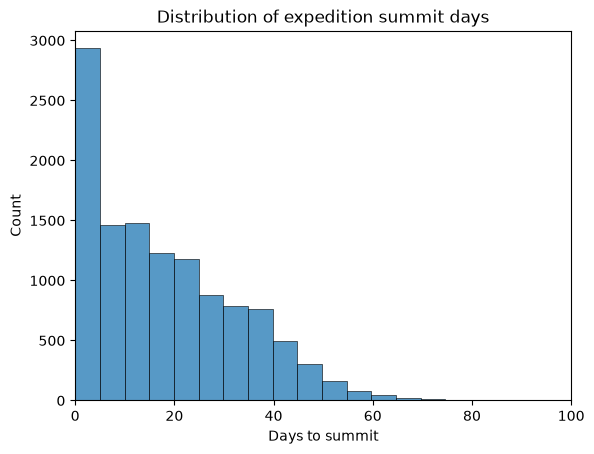

In [569]:
sns.histplot(data=df, x="smtdays", binwidth=5)
plt.title("Distribution of expedition summit days")
plt.xlabel("Days to summit")
plt.xlim((0, 100))
plt.show()

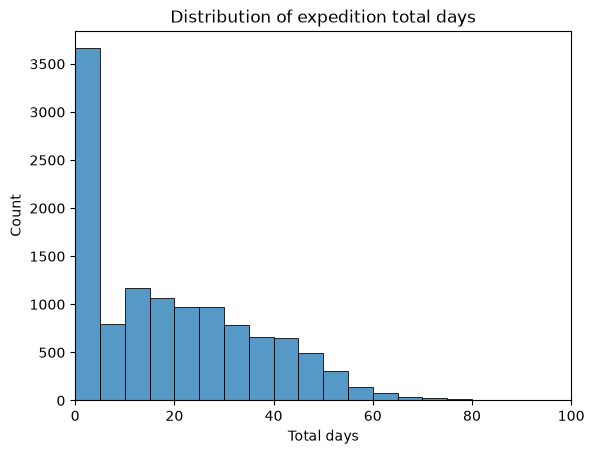

In [570]:
sns.histplot(data=df, x="totdays", binwidth=5)
plt.title("Distribution of expedition total days")
plt.xlabel("Total days")
plt.xlim((0, 100))
plt.show()

- _smtdays_ and _totdays_ have a right skew (not unexpected)
- **values can be derived from expedition dates and will therefore not be included models**

##### Camps and rope

In [73]:
df[['rope', 'camps']].describe()

,rope,camps
count,11854.000000,11854.000000
mean,167.211996,2.257972
std,660.835028,1.569480
min,0.000000,0.000000
25%,0.000000,1.000000
50%,0.000000,2.000000
75%,0.000000,3.000000
max,8700.000000,34.000000


##### Highpoint

In [74]:
df.highpoint.describe()

count    11854.000000
mean      7074.080479
std       1847.166856
min          0.000000
25%       6550.000000
50%       7152.000000
75%       8188.000000
max       8850.000000
Name: highpoint, dtype: float64

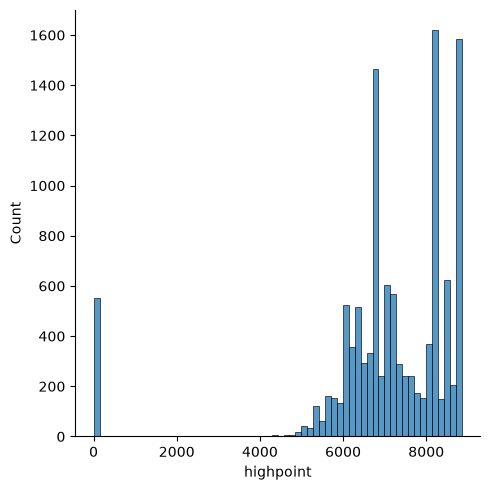

In [75]:
sns.displot(data=df, x="highpoint")
plt.show()

In [76]:
df.loc[df.highpoint == 0]

,expid,peakid,year,season,host,route1,route2,route3,route4,nation,...,accidents,achievment,agency,comrte,stdrte,primrte,primmem,primref,primid,chksum
23,ANN453101_1953,ANN4,1953,1,1,Reconnaissance from S,NaN,NaN,NaN,UK,...,NaN,NaN,NaN,None,None,False,False,None,NaN,5013
67,MAKA88104_1988,MAKA,1988,1,1,W Face,NaN,NaN,NaN,Switzerland,...,Troillet broken leg on approach,NaN,Asian Trekking,None,None,False,False,None,NaN,2978
87,ANN188102_1988,ANN1,1988,1,1,N Face,NaN,NaN,NaN,Mexico,...,NaN,NaN,Asian Trekking,None,True,False,False,None,NaN,5003
146,TUKU83301_1983,TUKU,1983,3,1,N Ridge,NaN,NaN,NaN,France,...,NaN,NaN,Great Himalayan Adventure (GHA),None,None,False,False,None,NaN,3648
204,BARU85302_1985,BARU,1985,3,1,NaN,NaN,NaN,NaN,France,...,None,NaN,NaN,None,None,False,False,None,NaN,5225
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11845,PERH25301_2025,PERH,2025,3,1,NaN,NaN,NaN,NaN,France,...,NaN,NaN,Himalayan Travellers Nepal,False,False,False,False,False,NaN,4815
11847,PUMO25301_2025,PUMO,2025,3,1,NaN,NaN,NaN,NaN,Czech Republic,...,NaN,NaN,14 Summits,False,False,False,False,False,NaN,4860
11849,PUTH25302_2025,PUTH,2025,3,1,NW Ridge,NaN,NaN,NaN,Poland,...,NaN,NaN,Outdoor Himalayan Treks,False,False,False,False,False,NaN,4905
11850,PUTH25303_2025,PUTH,2025,3,1,NW Ridge,NaN,NaN,NaN,Japan,...,NaN,NaN,Himalayan Sherpa Adventure,False,False,False,False,False,NaN,4905


- highoint variable is clean (no suspicious outliers or missing values)
- 

### Routes

In [246]:
print("Proportion of unique route names:", (df.route1.value_counts() == 1).mean().round(3))

Proportion of unique route names: 0.768


In [247]:
route_counts = df.groupby(['peakid', 'route1'], as_index=False)['expid'].count()
print("Number of peakid/route combinations:", route_counts.shape[0])
print("Percentage of repeated combinations:", 100 * (route_counts.expid > 1).mean().round(3))

Number of peakid/route combinations: 2422
Percentage of repeated combinations: 21.3


In [248]:
peak_routes = df.groupby('peakid', as_index=False).agg(
  expedition_count=pd.NamedAgg(column="expid", aggfunc="nunique"),
  route_count=pd.NamedAgg(column="route1", aggfunc="nunique"),
)
peak_routes["ratio"] = peak_routes.expedition_count / peak_routes.route_count

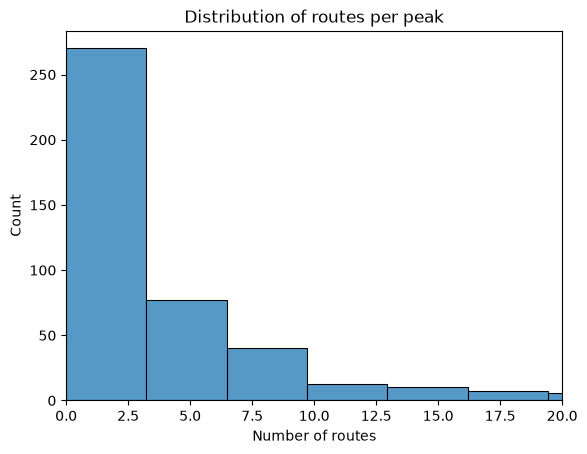

In [249]:
sns.histplot(data=peak_routes, x="route_count")
plt.title("Distribution of routes per peak")
plt.xlabel("Number of routes")
plt.xlim((0, 20))
plt.show()

In [250]:
peak_routes.route_count.describe()

count    439.000000
mean       5.517084
std       10.916204
min        0.000000
25%        1.000000
50%        2.000000
75%        5.500000
max      136.000000
Name: route_count, dtype: float64

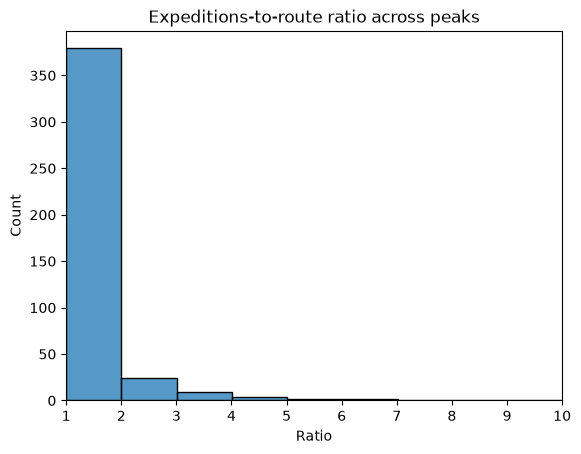

In [251]:
sns.histplot(data=peak_routes.loc[peak_routes.route_count > 0], x="ratio", binwidth=1)
plt.title("Expeditions-to-route ratio across peaks")
plt.xlabel("Ratio")
plt.xlim((1, 10))
plt.show()

In [252]:
peak_routes.loc[peak_routes.route_count > 0].ratio.describe()

count    428.000000
mean       1.773039
std        2.543009
min        1.000000
25%        1.000000
50%        1.200000
75%        1.666667
max       34.081633
Name: ratio, dtype: float64

The route variables in the expeditions dataset (route1, route2, route3, route4) are free-from, unstructured names given to the approach taken by an expedition up to a peak. Entries range from short, oft-repeated entries (e.g: SW Ridge, W Face) to unique idiosyncratic descriptions (e.g: _se face (from jyal), sw ridge (to kek1)_)

- there are 2422 different peak ID/route combinations in the dataset (approximately 80% are unique)
- on average, a single peak route has been taken by 1.67 expeditions
- routes may be modeled as a __high-cardinality dimension__

Despite the high frequency of unique values, there is a significant subset of frequently recurring peak routes worthy of investigating. A dataset could be built to answer questions such as:
- which route is most frequently used?
- what is the average time-to-summit for each route?
- which route has the highest success rate?

In [253]:
df[['route1', 'route2', 'route3', 'route4']].isna().mean()

route1    0.015438
route2    0.968703
route3    0.997469
route4    0.999578
dtype: float64

In [254]:
df.loc[df.route1.isna(), ['expid', 'termreason']].termreason.value_counts()

termreason
12    71
0     37
1     26
11    16
4      8
10     6
5      6
14     5
13     4
7      2
3      1
9      1
Name: count, dtype: int64

- Most expeditions have only one route
- Expeditions without a specified route most often did not attempt climb (termreason = 12)

#### Approach
I use a similar for describing the __approach__ variable as I did for the routes, and investigate how these variables relate.

In [255]:
df.approach.head(20)

0                   Marshyangdi->Hongde->Sabje Khola
1                   Marshyangdi->Hongde->Sabje Khola
2                Marshyangdi->Pisang->Salatang Khola
3                Marshyangdi->Pisang->Salatang Khola
4          Pokhara->Marshyangdi->Pisang->Sabje Khola
5                Marshyangdi->Pisang->Salatang Khola
6                               Madi Khola->Hogagoth
7         Dumre->Marshyangdi->Pisang->Salatang Khola
8                               Madi Khola->Hogagoth
9                               Madi Khola->Hogagoth
10                  Marshyangdi->Hongde->Sabje Khola
11                              Madi Khola->Hogagoth
12               Marshyangdi->Pisang->Salatang Khola
13                                               NaN
14                              Madi Khola->Hogagoth
15                              Madi Khola->Hogagoth
16                                               NaN
17                               Marshyangdi->Pisang
18                  Marshyangdi->Hongde->Sabje

In [256]:
df.approach = df.approach.str.lower()

In [257]:
print("Proportion of missing approach values:", df.approach.isna().mean().round(3))
print("Proportion of unique approach values:", (df.approach.value_counts() == 1).mean().round(3))
print("Number of unique approach entries:", df.approach.nunique())

Proportion of missing approach values: 0.535
Proportion of unique approach values: 0.823
Number of unique approach entries: 2654


In [258]:
df.approach.value_counts().sort_values(ascending=False)

approach
zhangmu->nyalam->tingri                        200
pangboche                                      132
ktm->tingri->bc                                132
lukla->namche->pangboche->everest bc           115
kodari->tingri->bc                             111
                                              ... 
from thami up bhote kosi river                   1
manang->khode->phu khola->phugaon                1
marshyangdi river->phu khola                     1
lukla->namche->gokyo->chola la-bc                1
lukla->namche->gokyo->chola->gorek shep->bc      1
Name: count, Length: 2654, dtype: int64

In [259]:
df[['peakid', 'approach']].head(10)

,peakid,approach
0,ANN2,marshyangdi->hongde->sabje khola
1,ANN2,marshyangdi->hongde->sabje khola
2,ANN2,marshyangdi->pisang->salatang khola
3,ANN2,marshyangdi->pisang->salatang khola
4,ANN2,pokhara->marshyangdi->pisang->sabje khola
5,ANN2,marshyangdi->pisang->salatang khola
6,ANN2,madi khola->hogagoth
7,ANN2,dumre->marshyangdi->pisang->salatang khola
8,ANN2,madi khola->hogagoth
9,ANN2,madi khola->hogagoth


In [260]:
print("Most peaks associates with one approach:", df.groupby('approach')['peakid'].nunique().max())
print("Most approaches associated with one peak:", df.groupby('peakid')['approach'].nunique().max())

Most peaks associates with one approach: 18
Most approaches associated with one peak: 307


In [261]:
print("Most routes associates with one approach:", df.groupby('approach')['route1'].nunique().max())
print("Most approaches associated with one route:", df.groupby('route1')['approach'].nunique().max())

Most routes associates with one approach: 36
Most approaches associated with one route: 394


In [262]:
# dataframe of unique peak-route-approache combinations and their dataset frequency
peak_route_approaches = df.loc[df.approach.notna()].groupby(['peakid', 'route1', 'approach'], as_index=False).size()

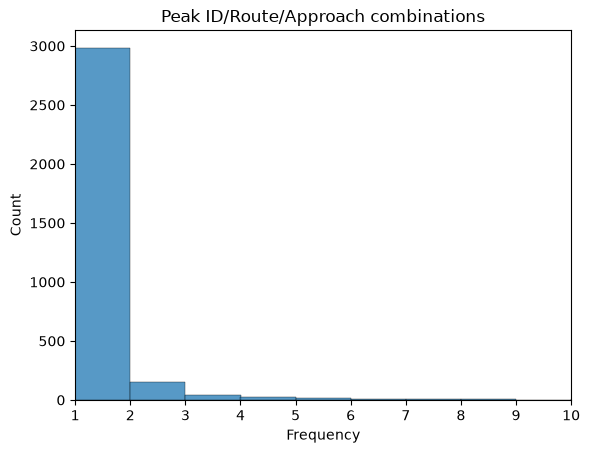

In [263]:
sns.histplot(data=peak_route_approaches, x="size", binwidth=1)
plt.title("Peak ID/Route/Approach combinations")
plt.xlabel("Frequency")
plt.xlim((1, 10))
plt.show()

In [264]:
# get the most frequently found combinations
peak_route_approaches.loc[peak_route_approaches["size"] > 20].sort_values(by="size", ascending=False)

,peakid,route1,approach,size
898,CHOY,nw side,zhangmu->nyalam->tingri,133
1489,EVER,s col-se ridge,lukla->namche->pangboche->everest bc,82
844,CHOY,nw side,ktm->tingri->bc,71
1351,EVER,n col-ne ridge,zhangmu->nyalam->tingri,65
1537,EVER,s col-se ridge,pangboche,64
1295,EVER,n col-ne ridge,kodari->tingri->bc,60
831,CHOY,nw side,kodari->tingri,50
832,CHOY,nw side,kodari->tingri->bc,50
1320,EVER,n col-ne ridge,lhasa->tingri,47
1301,EVER,n col-ne ridge,ktm->tingri->rongbuk bc,43


Similarly to routes, the __approach__ variable data takes the shape of free-form text with loose structure. Most entries consist of names separated by arrows ('->') describing the journey taken by the expedition.
- the approach variable has over 50% of missing values
- there are 2,654 different values for the approach variable in the dataset (82% of them are unique)

There is a subset of 33 peak/route/approach combinations that are repeated in the dataset (> 20 times), for which aggregated metrics could be computed such as success rate or time to summit.


#### Expedition timelines
The Expeditions dataset contains 3 date variables:
1. __bcdate__: date arrived at basecamp
2. __smtdate__: date reached the summit
3. __termdate__: date terminated

As is usual for date variables, I validate format and check for date inconsistencies.

In [265]:
df[['bcdate', 'smtdate', 'termdate']].dtypes

bcdate      object
smtdate     object
termdate    object
dtype: object

In [266]:
print(df.bcdate.notna().mean().round(3))
print(df.smtdate.notna().mean().round(3))
print(df.termdate.notna().mean().round(3))

0.836
0.932
0.717


In [267]:
df.bcdate = pd.to_datetime(df.bcdate, yearfirst=True)
df.smtdate = pd.to_datetime(df.smtdate, yearfirst=True)
df.termdate = pd.to_datetime(df.termdate, yearfirst=True)

In [268]:
print(df.bcdate.notna().mean().round(3))
print(df.smtdate.notna().mean().round(3))
print(df.termdate.notna().mean().round(3))

0.836
0.932
0.717


In [269]:
inconsistent_dates = df.loc[
  (df.smtdate < df.bcdate) | (df.termdate < df.bcdate) | (df.termdate < df.smtdate), 
  ['bcdate', 'smtdate', 'smtdays', 'termdate', 'totdays']]
print(f"Number of instances of inconsistent dates: {inconsistent_dates.shape[0]}")
inconsistent_dates.head(10)

Number of instances of inconsistent dates: 59


,bcdate,smtdate,smtdays,termdate,totdays
4416,2003-10-07,2003-10-20,13,2003-10-11,4
4632,2004-04-03,2004-05-26,53,2004-05-20,47
4669,2004-08-24,2004-09-18,25,2004-09-04,11
4676,NaT,2004-09-27,0,2004-09-03,0
4694,2004-09-05,2004-09-25,20,2004-09-05,0
4724,2004-10-12,2004-12-12,61,2004-10-19,7
4947,2005-04-01,2005-05-21,50,2005-04-22,21
4972,2005-04-09,2005-05-31,52,2005-05-24,45
4978,2005-04-09,2005-05-30,51,2005-05-03,24
4981,2005-04-05,2005-05-30,55,2005-05-02,27


In [270]:
df['days_to_summit'] = (df.smtdate - df.bcdate).dt.days
df.loc[
  df.bcdate.notna() & df.smtdate.notna() & (df.days_to_summit != df.smtdays),
  ['bcdate', 'smtdate', 'smtdays', 'days_to_summit']
].head(10)

,bcdate,smtdate,smtdays,days_to_summit
2092,1997-01-07,1997-01-29,388,22.0
3424,1999-09-09,1999-09-26,0,17.0
5151,2006-01-14,2006-01-24,0,10.0
5490,2006-11-06,2006-11-08,0,2.0
5921,2008-01-13,2008-02-02,0,20.0
8506,2013-09-14,2013-09-20,0,6.0


In [271]:
df['days_to_term'] = (df.termdate - df.bcdate).dt.days
df.loc[
  df.bcdate.notna() & df.termdate.notna() & (df.days_to_term != df.totdays),
  ['bcdate', 'termdate', 'totdays', 'days_to_term']
]

,bcdate,termdate,totdays,days_to_term
4258,2003-04-09,2003-05-31,50,52.0


In [272]:
print(df.loc[df.bcdate.notna() & df.smtdate.isna() & df.smtdays > 0].shape)
print(df.loc[df.bcdate.isna() & df.termdate.notna() & df.totdays > 0].shape)

(0, 68)
(0, 68)


In [273]:
print(df.bcdate.notna().mean().round(3))
print(df.smtdate.notna().mean().round(3))
print(df.termdate.notna().mean().round(3))

0.836
0.932
0.717


Note:
- date format is consistent across rows and columns (yyyy-mm-dd)
- all date variables have less than 30% of missing values
- there are 59 cases (< 1%) of data inconsistency (impossible timelines)
- the derived _smtdays_ and _totdays_ are redundant and contain mistakes (to be left out)

In [274]:
for col in df.columns:
  print(f"{col} ({df[col].dtype})")

expid (str)
peakid (str)
year (str)
season (int64)
host (int64)
route1 (str)
route2 (str)
route3 (str)
route4 (str)
nation (str)
leaders (str)
sponsor (str)
success1 (bool)
success2 (bool)
success3 (bool)
success4 (bool)
ascent1 (str)
ascent2 (str)
ascent3 (str)
ascent4 (str)
claimed (bool)
disputed (bool)
countries (str)
approach (str)
bcdate (datetime64[s])
smtdate (datetime64[s])
smttime (str)
smtdays (int64)
totdays (int64)
termdate (datetime64[s])
termreason (int64)
termnote (str)
highpoint (int64)
traverse (bool)
ski (bool)
parapente (bool)
camps (int64)
rope (int64)
totmembers (int64)
smtmembers (int64)
mdeaths (int64)
tothired (int64)
smthired (int64)
hdeaths (int64)
nohired (bool)
o2used (bool)
o2none (bool)
o2climb (bool)
o2descent (bool)
o2sleep (bool)
o2medical (bool)
o2taken (bool)
o2unkwn (bool)
othersmts (str)
campsites (str)
routememo (str)
accidents (str)
achievment (str)
agency (str)
comrte (object)
stdrte (object)
primrte (bool)
primmem (bool)
primref (object)
primid

# Members

In [275]:
member_file_name = data_dir / "members.DBF"
df = read_dbf(member_file_name)

In [276]:
df.head()

,expid,membid,peakid,myear,mseason,fname,lname,sex,age,yob,...,membermemo,necrology,msmtbid,msmtterm,hcn,mchksum,msmtnote1,msmtnote2,msmtnote3,deathrte
0,AMAD78301,01,AMAD,1978,3,Jean Robert,Clemenson,M,0,1938,...,NaN,NaN,1,4,0,2426937,NaN,NaN,NaN,NaN
1,AMAD78301,02,AMAD,1978,3,Bernard,Dufour,M,0,1936,...,NaN,NaN,1,4,0,2426501,NaN,NaN,NaN,NaN
2,AMAD78301,03,AMAD,1978,3,Philippe,Gerard,M,0,1950,...,NaN,NaN,1,4,0,2431569,NaN,NaN,NaN,NaN
3,AMAD78301,04,AMAD,1978,3,Eric,Lasserre,M,0,1937,...,NaN,NaN,1,4,0,2426809,NaN,NaN,NaN,NaN
4,AMAD78301,05,AMAD,1978,3,Guy,Peters,M,0,1944,...,NaN,NaN,1,4,0,2429215,NaN,NaN,NaN,NaN


In [277]:
df.shape

(94999, 77)

In [278]:
df.isna().mean().sort_values(ascending=False)[:15]

msmttime3     0.999926
msmtdate3     0.999768
injurytime    0.999084
msmttime2     0.997147
msmtdate2     0.994895
deathtime     0.993916
injurydate    0.988874
deathdate     0.987789
deathnote     0.978863
necrology     0.945652
membermemo    0.868767
mo2note       0.838304
msmtnote3     0.767787
msmtnote2     0.767208
msmtnote1     0.764208
dtype: float64

In [279]:
df.dtypes.value_counts()

bool       27
str        21
int64      19
object      6
float64     4
Name: count, dtype: int64

Notes:
- high-dimensional dataset with text, numerical, and date variables
- nested summit information in wide format (msmtdate1-3, mroute1-3, msuccess1-3,...)

In [280]:
df.select_dtypes(include=[str]).head()

,expid,membid,peakid,myear,fname,lname,sex,yob,citizen,status,...,occupation,msmttime1,msmttime2,msmttime3,mo2note,deathtime,injurytime,deathnote,membermemo,necrology
0,AMAD78301,01,AMAD,1978,Jean Robert,Clemenson,M,1938,France,Leader,...,Alpine guide,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AMAD78301,02,AMAD,1978,Bernard,Dufour,M,1936,France,Deputy Leader,...,Alpine guide,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AMAD78301,03,AMAD,1978,Philippe,Gerard,M,1950,France,Climber,...,Professional photographer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AMAD78301,04,AMAD,1978,Eric,Lasserre,M,1937,France,Exp Doctor,...,Physician,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AMAD78301,05,AMAD,1978,Guy,Peters,M,1944,France,Climber,...,Alpine guide,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [281]:
df.expid = df.expid.str.cat(df.myear, sep="_")
df = df.drop(["peakid", "myear", "mseason", "age"], axis=1)

In [282]:
assert df.groupby(['expid', 'membid']).size().max() == 1 # unique
assert df[['expid', 'membid']].notna().all().all() # not null

> Expedition ID and member ID combine to form a valid composite primary key.

In [283]:
df.msmtdate1 = pd.to_datetime(df.msmtdate1, yearfirst=True)
df.msmtdate2 = pd.to_datetime(df.msmtdate2, yearfirst=True)
df.msmtdate3 = pd.to_datetime(df.msmtdate3, yearfirst=True)
df.deathdate = pd.to_datetime(df.deathdate, yearfirst=True)
df.injurydate = pd.to_datetime(df.injurydate, yearfirst=True)

In [284]:
df.select_dtypes(include=[bool]).mean()

leader        0.125496
deputy        0.018348
bconly        0.052958
nottobc       0.012569
support       0.002358
disabled      0.001284
hired         0.232371
sherpa        0.200718
tibetan       0.022337
msuccess      0.432120
mclaimed      0.000979
mdisputed     0.001400
msolo         0.001368
mtraverse     0.003979
mski          0.004147
mparapente    0.000358
mhighpt       0.565764
mo2used       0.276024
mo2none       0.676565
mo2climb      0.264982
mo2descent    0.002063
mo2sleep      0.118970
mo2medical    0.003590
death         0.012495
ams           0.001726
weather       0.000632
injury        0.018927
dtype: float64